In [19]:
import numpy as np

In [20]:
layer_dims = []
layers = int(input("Enter the number of hidden layers :/n"))
for layer in range(layers):
    layer_dims.append(int(input(f"layer number {layer + 1} : ")))

In [21]:
def initialize_parameters(layer_dims, seed, modes):
    """
    layer_dims : list of ints, e.g. [784, 128, 64, 10]
    returns: dict with keys "W1","b1","W2","b2", ...
    In code, that is np.random.randn(n_l, n_prev) * np.sqrt(2.0 / n_prev)
    """
    params = {}
    np.random.seed(seed)
    if modes == "he":
        for l in range(1, len(layer_dims)):
            params[f"W{l}"] = np.random.randn(
                layer_dims[l], layer_dims[l - 1]
            ) * np.sqrt(2.0 / layer_dims[l - 1])
            params[f"b{l}"] = np.zeros((layer_dims[l], 1))
    else:
        for l in range(1, len(layer_dims)):
            params[f"W{l}"] = np.random.randn(layer_dims[l], layer_dims[l - 1]) * mode
            params[f"b{l}"] = np.zeros((layer_dims[l], 1))

    return params

In [22]:
class NeuralNetwork:
    def __init__(self, layer_dims, seed=0, modes="he"):
        self.params = initialize_parameters(layer_dims, seed, modes)
        self.layer_dims = layer_dims

    def relu(self, Z):
        return np.maximum(0, Z)

    def Softmax(self, z):
        z = z - np.max(z, keepdims=True, axis=0)
        return np.exp(z) / np.sum(np.exp(z), keepdims=True, axis=0)

    def layer_forward(self, A_prev, W, b, activation):
        """
        A_prev :(n_prev,m)
        W :(n_l,n_prev)
        b :(n_l,1)
        activation:"relu"or"softmax"
        returns :A,Z
        """
        Z = np.dot(W, A_prev) + b
        A = self.relu(Z) if activation == "relu" else self.Softmax(Z)
        return A, Z

    def model_forward(self, X, parameters):
        """
        returns : AL, cache
        cache holds every A and Z you will need in backprop
        """
        cache = {}
        cache["A0"] = X
        A_prev = X
        layer_dims = self.layer_dims

        for l in range(1, len(layer_dims) - 1):
            A, Z = self.layer_forward(
                A_prev=A_prev,
                W=parameters[f"W{l}"],
                b=parameters[f"b{l}"],
                activation="relu",
            )
            cache[f"A{l}"] = A
            cache[f"Z{l}"] = Z
            A_prev = A

        AL, ZL = self.layer_forward(
            A_prev=A_prev,
            W=parameters[f"W{len(layer_dims) - 1}"],
            b=parameters[f"b{len(layer_dims) - 1}"],
            activation="softmax",
        )
        cache[f"A{len(layer_dims) - 1}"] = AL
        cache[f"Z{len(layer_dims) - 1}"] = ZL
        return AL, cache

    def compute_cost(self, AL, Y):
        """
        AL : (10, m) predicted probabilities
        Y : (10, m) one-hot labels
        returns : scalar
        """
        m = Y.shape[1]
        scalar = (-1 / m) * np.sum(Y * np.log(AL + 1e-12))
        return np.squeeze(scalar)

    def layer_backward(self, dA, Z, W, b, A_prev, activation):
        """
        dA :(n_l,m) gradient arriving from the layer above
        returns:dW,db,dA_prev
        """
        m = dA.shape[1]
        dz = dA * (Z > 0)
        dw = (1 / m) * dz @ (A_prev.T)
        db = (1 / m) * np.sum(dz, axis=1, keepdims=True)
        dA_prev = (W.T) @ dz
        return dw, db, dA_prev

    def model_backward(self, AL, Y, cache, parameters):
        """
        returns :grads,adictwith"dW1","db1","dW2","db2",...
        """
        grads = {}
        layers = len(parameters) // 2
        m = Y.shape[1]
        dz = AL - Y
        dwl = (1 / m) * dz @ (cache[f"A{layers - 1}"].T)
        dbl = (1 / m) * np.sum(dz, axis=1, keepdims=True)
        dA_prev = (parameters[f"W{layers}"].T) @ dz

        grads[f"dW{layers}"] = dwl
        grads[f"db{layers}"] = dbl
        for l in range(layers - 1, 0, -1):
            dw, db, dA_prev = self.layer_backward(
                dA_prev,
                cache[f"Z{l}"],
                parameters[f"W{l}"],
                parameters[f"b{l}"],
                cache[f"A{l - 1}"],
                activation="relu",
            )

            grads[f"dW{l}"] = dw
            grads[f"db{l}"] = db
        return grads

    def update_parameters(self, parameters, grads, learning_rate):
        """
        returns : updated parameters dict
        """
        layers = len(parameters) // 2
        for l in range(1, layers + 1):
            parameters[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
            parameters[f"b{l}"] -= learning_rate * grads[f"db{l}"]
        return parameters

    def get_mini_batches(self, X, y, batch_size):
        mini_batches = []
        m = X.shape[1]  # Number of data samples

        # 1. Create a synchronized random permutation of indices
        permutation = np.random.permutation(m)
        shuffled_X = X[:, permutation]
        shuffled_y = y[:, permutation]

        # 2. Slice into mini-batches
        num_complete_batches = m // batch_size
        for k in range(num_complete_batches):
            batch_X = shuffled_X[:, k * batch_size : (k + 1) * batch_size]
            batch_y = shuffled_y[:, k * batch_size : (k + 1) * batch_size]
            mini_batches.append((batch_X, batch_y))

        # 3. Handle the leftover data (the final partial batch)
        if m % batch_size != 0:
            batch_X = shuffled_X[:, num_complete_batches * batch_size :]
            batch_y = shuffled_y[:, num_complete_batches * batch_size :]
            mini_batches.append((batch_X, batch_y))

        return mini_batches

    def train(self, X, Y, epochs, batch_size, learning_rate):
        # data
        self.loss_part_A = []
        X = X.reshape(-1, self.layer_dims[0]).astype(np.float64) / 255.0
        X = X.T  # (784, m)-- examples in COLUMNS
        Y = np.eye(self.layer_dims[-1])[Y].T  # (10, m)

        for epoch in range(epochs):
            batches = self.get_mini_batches(X, Y, batch_size)
            epoch_cost = 0
            for batch_X, batch_y in batches:
                AL, cache = self.model_forward(batch_X, self.params)
                epoch_cost += self.compute_cost(AL, batch_y)
                grads = self.model_backward(AL, batch_y, cache, self.params)
                self.params = self.update_parameters(self.params, grads, learning_rate)
            # if epoch % 10 == 0:
            print(
                f"Cost after iteration {epoch + 1}: {(epoch_cost / len(batches)):.4f}"
            )
            self.loss_part_A.append(epoch_cost / len(batches))
        return self.loss_part_A

    def predict(self, X):
        X = X.reshape(-1, self.layer_dims[0]).astype(np.float64) / 255.0
        X = X.T
        AL, _ = self.model_forward(X, self.params)
        pred = np.argmax(AL, axis=0)
        return pred

In [23]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

X, y = fetch_openml(
    "mnist_784", version=1, return_X_y=True, as_frame=False, parser="auto"
)
y = y.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=10000, random_state=42, stratify=y
)

In [24]:
import time

In [25]:
# run Part A once with [784, 128, 64, 10]
nn = NeuralNetwork(layer_dims, 0)
start_time = time.perf_counter()
loss_part_A = nn.train(
    X_train,
    y_train,
    10,
    64,
    0.1,
)
part_A_time = time.perf_counter() - start_time
print(f" Training Time for part_A: {part_A_time:.2f} seconds")
pred = nn.predict(X_test)
accuracy = np.mean(pred == y_test) * 100
print(f"test accuracy:{accuracy:.2f}%")

Cost after iteration 1: 0.3247
Cost after iteration 2: 0.1492
Cost after iteration 3: 0.1054
Cost after iteration 4: 0.0821
Cost after iteration 5: 0.0670
Cost after iteration 6: 0.0544
Cost after iteration 7: 0.0457
Cost after iteration 8: 0.0391
Cost after iteration 9: 0.0326
Cost after iteration 10: 0.0279
 Training Time for part_A: 22.87 seconds
test accuracy:95.01%


In [26]:
layer_dims = []
layers = int(input("Enter the number of hidden layers :/n"))
for layer in range(layers):
    layer_dims.append(int(input(f"layer number {layer + 1} : ")))

In [27]:
# run Part A with [784, 256,128, 64, 10]
nn = NeuralNetwork(layer_dims, 0)
_ = nn.train(
    X_train,
    y_train,
    10,
    64,
    0.1,
)
pred = nn.predict(X_test)
accuracy = np.mean(pred == y_test) * 100
print(f"test accuracy:{accuracy:.2f}%")

Cost after iteration 1: 0.3022
Cost after iteration 2: 0.1190
Cost after iteration 3: 0.0811
Cost after iteration 4: 0.0613
Cost after iteration 5: 0.0464
Cost after iteration 6: 0.0360
Cost after iteration 7: 0.0279
Cost after iteration 8: 0.0212
Cost after iteration 9: 0.0151
Cost after iteration 10: 0.0115
test accuracy:97.83%


In [28]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset

In [29]:
layer_dims = []
layers = int(input("Enter the number of hidden layers :/n"))
for layer in range(layers):
    layer_dims.append(int(input(f"layer number {layer + 1} : ")))

In [ ]:
class TorchNet(nn.Module):
    def __init__(self, layer_dims):
        """
        (Replaces __init__)
        """
        super().__init__()
        # Use nn.ModuleList so PyTorch registers all weights in model.parameters()
        self.layers = nn.ModuleList()

        for l in range(len(layer_dims) - 1):
            #!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! my code !!!
            # self.layer[f"{l + 1}"] = nn.Linear(layer_dims[l], layer_dims[l + 1])
            #!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! my code !!!
            self.layers.append(nn.Linear(layer_dims[l], layer_dims[l + 1]))

    def forward(self, x):
        """ "
        (Replaces model_forward, layer_forward)
        """
        x = x.view(x.size(0), -1)
        #!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! my code !!!
        # temp = x
        # for l in range(len(layer_dims) - 1):
        #     self.z[f"{l + 1}"] = self.layer[f"{l + 1}"](temp)
        #     if l != len(layer_dims):
        #         self.a[f"{l + 1}"] = torch.relu(self.z[f"{l + 1}"])
        #         temp = self.a1[f"{l + 1}"]
        # return self.z[f"{len(layer_dims) + 1}"]
        #!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!! my code !!!
        # Loop through layers dynamically
        for l in range(len(self.layers) - 1):
            x = F.relu(self.layers[l](x))

        # Output layer (returns raw logits without activation)
        logits = self.layers[-1](x)
        return logits

    def train_model(self, model, train_loader, epochs=10, lr=0.1):

        criterion = (
            nn.CrossEntropyLoss()
        )  # LOSS FUNCTION (Replaces compute_cost + manual Softmax)
        # Combined Softmax + CrossEntropy for maximum numerical stability

        optimizer = optim.SGD(
            model.parameters(), lr=lr
        )  # OPTIMIZER (Replaces update_parameters loop)
        # Manages W = W - lr * dW automatically across all layers
        # optimizer.zero_grad() is necessary because PyTorch accumulates (adds up) gradients on every backward pass instead of overwriting them.
        # If you do not clear them out, the gradients from your previous training step will mix with your current step, ruining your model's updates.

        model.train()  # Sets model to training mode

        self.loss_part_B = []

        for epoch in range(epochs):
            running_loss = 0
            for batch_X, batch_y in train_loader:
                optimizer.zero_grad()
                # If you keep calling .backward() across training iterations without zeroing the gradients, the stored gradients grow endlessly. This causes exploding weight updates during optimization.
                # Because NumPy uses standard array assignment (=), every new backward pass completely replaces the old gradient matrix with fresh calculations from the current iteration
                output = model(batch_X)  # Forward pass (Calls model.forward(batch_x))
                loss = criterion(output, batch_y)  # Compute cost
                loss.backward()  # Backward pass : Replaces model_backward & autograd calculates dW, db
                optimizer.step()  # Parameter update (Replaces update_parameters)
                running_loss += loss.item()
            print(
                f"Epoch {epoch + 1} | Average Loss: {(running_loss / len(train_loader)):.4f}"
            )
            self.loss_part_B.append(running_loss / len(train_loader))
        return self.loss_part_B

    def predict(self, model, test_loader):  # (Replaces predict)
        model.eval()  # Sets model to evaluation mode
        correct = 0
        total = 0

        # torch.no_grad() disables autograd tracking to save memory/speed up evaluation
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                logits = model(batch_x)
                predictions = torch.argmax(logits, dim=1)
                total += batch_y.size(0)
                correct += (predictions == batch_y).sum().item()

        acc = (correct / total) * 100
        print(f"Test Set Accuracy: {acc:.2f}%")

In [31]:
# 1. Define transformation to convert images to PyTorch Tensors
transform = transforms.ToTensor()

# 2. Download/load MNIST training and testing sets
train_dataset = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

# 3. Wrap datasets inside DataLoaders
train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

In [32]:
model = TorchNet(layer_dims)
# Ensure GPU work completes before starting the clock
if torch.cuda.is_available():
    torch.cuda.synchronize()
start_time = time.perf_counter()
loss_part_B = model.train_model(model, train_loader, 10, 0.1)
# Wait for GPU to finish all queued execution
if torch.cuda.is_available():
    torch.cuda.synchronize()
part_B_time = time.perf_counter() - start_time
print(f" Training Time for part_B: {part_B_time:.2f} seconds")
model.predict(model, test_loader)

Epoch 0 | Average Loss: 0.4973
Epoch 1 | Average Loss: 0.1924
Epoch 2 | Average Loss: 0.1328
Epoch 3 | Average Loss: 0.1006
Epoch 4 | Average Loss: 0.0803
Epoch 5 | Average Loss: 0.0667
Epoch 6 | Average Loss: 0.0560
Epoch 7 | Average Loss: 0.0477
Epoch 8 | Average Loss: 0.0412
Epoch 9 | Average Loss: 0.0349
 Training Time for part_B: 150.24 seconds
Test Set Accuracy: 97.74%


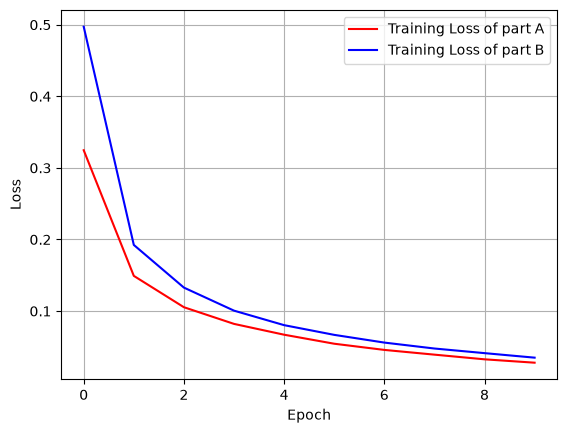

In [33]:
import matplotlib.pyplot as plt

plt.plot(loss_part_A, label="Training Loss of part A", c="r")
plt.plot(loss_part_B, label="Training Loss of part B", c="b")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

In [34]:
layer_dims = []
layers = int(input("Enter the number of hidden layers :/n"))
for layer in range(layers):
    layer_dims.append(int(input(f"layer number {layer + 1} : ")))

In [35]:
# The initialization experiment (Section 3): loss after one epoch with He, with * 0.01, and with * 1.0. Two or three sentences on what you observed.
modes = ["he", 0.01, 1.0]
loss_track = []
for mode in modes:
    nn = NeuralNetwork(layer_dims, 0, mode)
    loss = nn.train(
        X_train,
        y_train,
        1,
        64,
        0.1,
    )
    loss_track.append(loss)
for mode, loss in zip(modes, loss_track):
    print(f"for mode : {mode} , the loss is {loss[0]:.4}")


Cost after iteration 1: 0.3247
Cost after iteration 1: 1.2671
Cost after iteration 1: 2.4587
for mode : he , the loss is 0.3247
for mode : 0.01 , the loss is 1.267
for mode : 1.0 , the loss is 2.459


***Scaling weights by 0.01 resulted in extremely small gradients that stalled learning (loss remained high near ~2.30), whereas scaling by 1.0 caused exploding outputs and unstable activations that severely hindered training. Consequently, proper variance scaling like He initialization is essential for deep networks with ReLU activations to avoid vanishing or exploding signals."***

***for part_A : the first problem occurred is handeling the input shape to the required shape format , like making it the shape of (features , samples)***

***for part_B : the first problem occurred is making a dictionary to save the parameters without calling nn.modulelist() and that will not be seen by the model !***